# Realce e Equalização de Imagens

Neste projeto aplicamos técnicas de realce em imagens de baixa qualidade, como ajuste de brilho e contraste, correção gama, transformação logarítmica, equalização de histograma e CLAHE.

In [12]:
%pip install -q kagglehub scikit-image

/Users/gepetojj/Documents/projetos/ifal/realce/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
import glob, random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import kagglehub

plt.rcParams["figure.dpi"] = 80

## Dataset

Baixamos o dataset e sorteamos algumas imagens do conjunto de teste.

In [14]:
caminho = kagglehub.dataset_download("balraj98/berkeley-segmentation-dataset-500-bsds500")
arquivos = sorted(glob.glob(f"{caminho}/images/test/*.jpg"))

N_IMAGENS = 30
random.seed(0)
amostra = random.sample(arquivos, N_IMAGENS)
imagens = [cv2.imread(a, cv2.IMREAD_GRAYSCALE) for a in amostra]

## Funções auxiliares

In [15]:
def mostrar(lista, titulos, hist=False):
    n = len(lista)
    _, ax = plt.subplots(2 if hist else 1, n, figsize=(3 * n, 5 if hist else 2.6), squeeze=False)

    for i, (img, t) in enumerate(zip(lista, titulos)):
        ax[0, i].imshow(img, cmap="gray", vmin=0, vmax=255)
        ax[0, i].set_title(t, fontsize=10)
        ax[0, i].axis("off")

        if hist:
            ax[1, i].hist(img.ravel(), bins=64, range=(0, 255), color="gray")
            ax[1, i].set_yticks([])

    plt.tight_layout()
    plt.show()

#Aplica uma função em cada pixel
def aplicar(img, f):
    lut = np.clip(f(np.arange(256, dtype=np.float64)), 0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

## Brilho e contraste

Cada pixel é multiplicado por um ganho (contraste) e somado a um deslocamento (brilho). Somar só desloca o histograma, e multiplicar estica ou comprime.

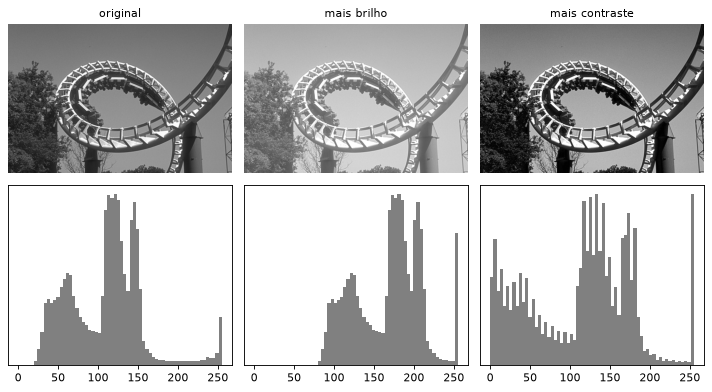

In [16]:
img = imagens[2]

# alpha é o contraste e beta é o brilho
mostrar(
    [img, cv2.convertScaleAbs(img, alpha=1.0, beta=60), cv2.convertScaleAbs(img, alpha=1.6, beta=-60)],
    ["original", "mais brilho", "mais contraste"],
    hist=True,
)

## Degradações

- **baixo contraste**: todos os tons comprimidos numa faixa estreita de cinza.
- **escura**: tons perto do preto.
- **superexposta**: tons perto do branco.

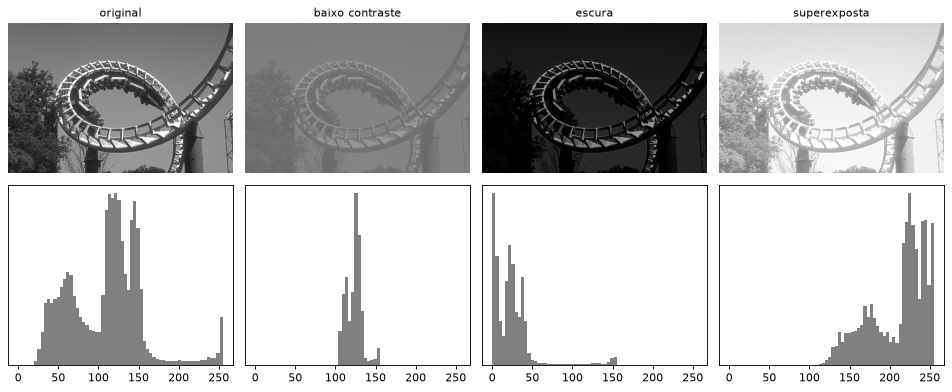

In [17]:
DEGRADACOES = {
    "baixo contraste": lambda im: aplicar(im, lambda r: 100 + r * 55 / 255),
    "escura": lambda im: aplicar(im, lambda r: 255 * (r / 255) ** 2.5 * 0.6),
    "superexposta": lambda im: aplicar(im, lambda r: 255 * (r / 255) ** 0.4 * 1.2),
}

mostrar([img] + [d(img) for d in DEGRADACOES.values()], ["original", *DEGRADACOES], hist=True)

## Realce

- Alongamento de contraste: estica os tons para ocupar toda a faixa de 0 a 255.
- Correção gama: clareia ou escurece os tons médios. O valor de gama é escolhido automaticamente para levar o brilho médio da imagem para o meio da escala.
- Logarítmica: clareia bastante os tons escuros e comprime os claros.
- Equalização de histograma: redistribui os tons para que todos apareçam com frequência parecida.
- CLAHE: equalização feita em blocos da imagem, com um limite que evita exagerar o contraste e o ruído.

In [18]:
def alongamento(im):
    return cv2.normalize(im, None, 0, 255, cv2.NORM_MINMAX)

def gama(im):
    media = np.clip(im.mean() / 255, 0.01, 0.99)
    g = np.log(0.5) / np.log(media)
    return aplicar(im, lambda r: 255 * (r / 255) ** g)

def logaritmica(im):
    return aplicar(im, lambda r: 255 * np.log1p(r) / np.log(256))

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

TECNICAS = {
    "sem realce": lambda im: im,
    "alongamento": alongamento,
    "gama": gama,
    "logarítmica": logaritmica,
    "equalização": cv2.equalizeHist,
    "CLAHE": clahe.apply,
}

## Comparação

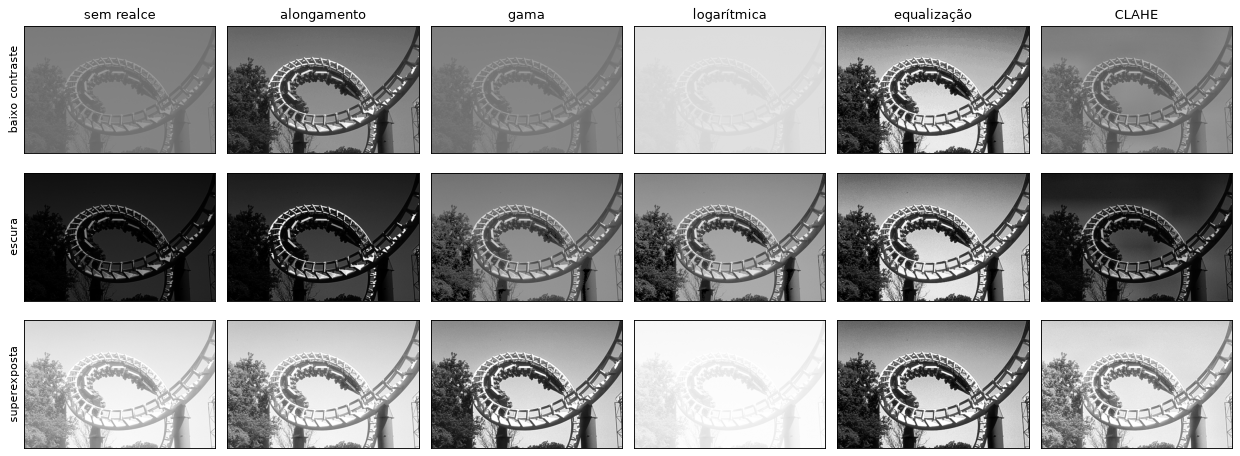

In [19]:
fig, ax = plt.subplots(len(DEGRADACOES), len(TECNICAS), figsize=(2.6 * len(TECNICAS), 2 * len(DEGRADACOES)))

for i, (nome_d, degradar) in enumerate(DEGRADACOES.items()):
    ruim = degradar(img)

    for j, (nome_t, realcar) in enumerate(TECNICAS.items()):
        ax[i, j].imshow(realcar(ruim), cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
        
        if i == 0: 
            ax[i, j].set_title(nome_t)

        if j == 0: 
            ax[i, j].set_ylabel(nome_d)

plt.tight_layout()
plt.show()

### Equalização global vs CLAHE

A equalização global usa um único histograma para a imagem inteira e pode estourar regiões muito claras ou muito escuras. O CLAHE ajusta cada região de forma separada, então preserva melhor os detalhes.

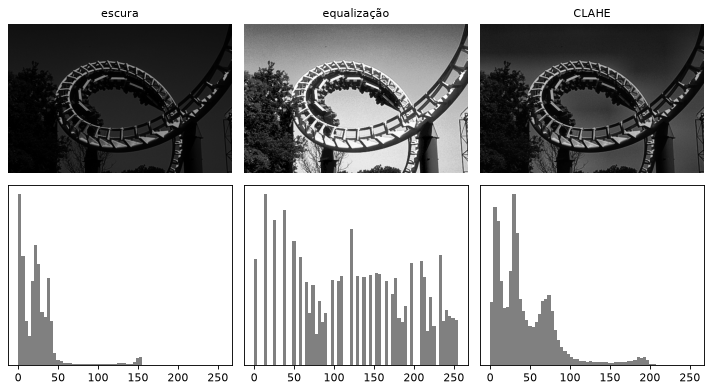

In [20]:
escura = DEGRADACOES["escura"](img)

mostrar([escura, cv2.equalizeHist(escura), clahe.apply(escura)], ["escura", "equalização", "CLAHE"], hist=True)